# Connected IQP: uniform-initialization follow-up
This notebook displays the paper's recorded 20-seed follow-up without training. The same previously inspected test seeds were reused, so this is an exploratory initialization comparison. Original and uniform results are both retained.
Training implementation: `connected_iqp_uniform_test.py`. QASP is installed separately from INESCTEC/qasp.

In [1]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image
REPO = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p/'REPOSITORY_PROVENANCE.json').is_file())
FOLDER = REPO/'results/connected_iqp_uniform_initialization'
report = json.loads((FOLDER/'comparison.json').read_text())
rows = ['| Model | Parameters | AUC | Episodes to criterion | Solved | Held-out return |', '|---|---:|---:|---:|---:|---:|']
for name, s in report['summary'].items():
    rows.append(f"| {name} | {s['parameters']} | {s['auc']['mean']:.4f} | {s['solve_episode']['mean']:.2f} | {s['solved']}/20 | {s['heldout']['mean']:.2f} |")
display(Markdown('\n'.join(rows)))


| Model | Parameters | AUC | Episodes to criterion | Solved | Held-out return |
|---|---:|---:|---:|---:|---:|
| iqp_connected_uniform | 139 | 0.7615 | 315.90 | 20/20 | 196.99 |
| iqp_connected | 139 | 0.9319 | 171.45 | 20/20 | 199.11 |
| mlp_h01_lr0p1 | 9 | 0.7229 | 374.45 | 15/20 | 191.25 |
| mlp_h02_lr0p1 | 16 | 0.7985 | 277.70 | 18/20 | 197.10 |
| mlp_h04_lr0p1 | 30 | 0.8469 | 263.65 | 17/20 | 191.58 |
| mlp_h06_lr0p1 | 44 | 0.8631 | 261.90 | 17/20 | 193.85 |
| mlp_h09_lr0p1 | 65 | 0.8428 | 309.75 | 16/20 | 187.60 |
| mlp_h12_lr0p03 | 86 | 0.8413 | 274.70 | 18/20 | 198.24 |
| mlp_h16_lr0p1 | 114 | 0.7941 | 323.15 | 16/20 | 185.79 |
| mlp_h19_lr0p03 | 135 | 0.8680 | 236.50 | 20/20 | 198.96 |
| mlp_h12_lr0p1 | 86 | 0.8591 | 261.60 | 17/20 | 188.72 |

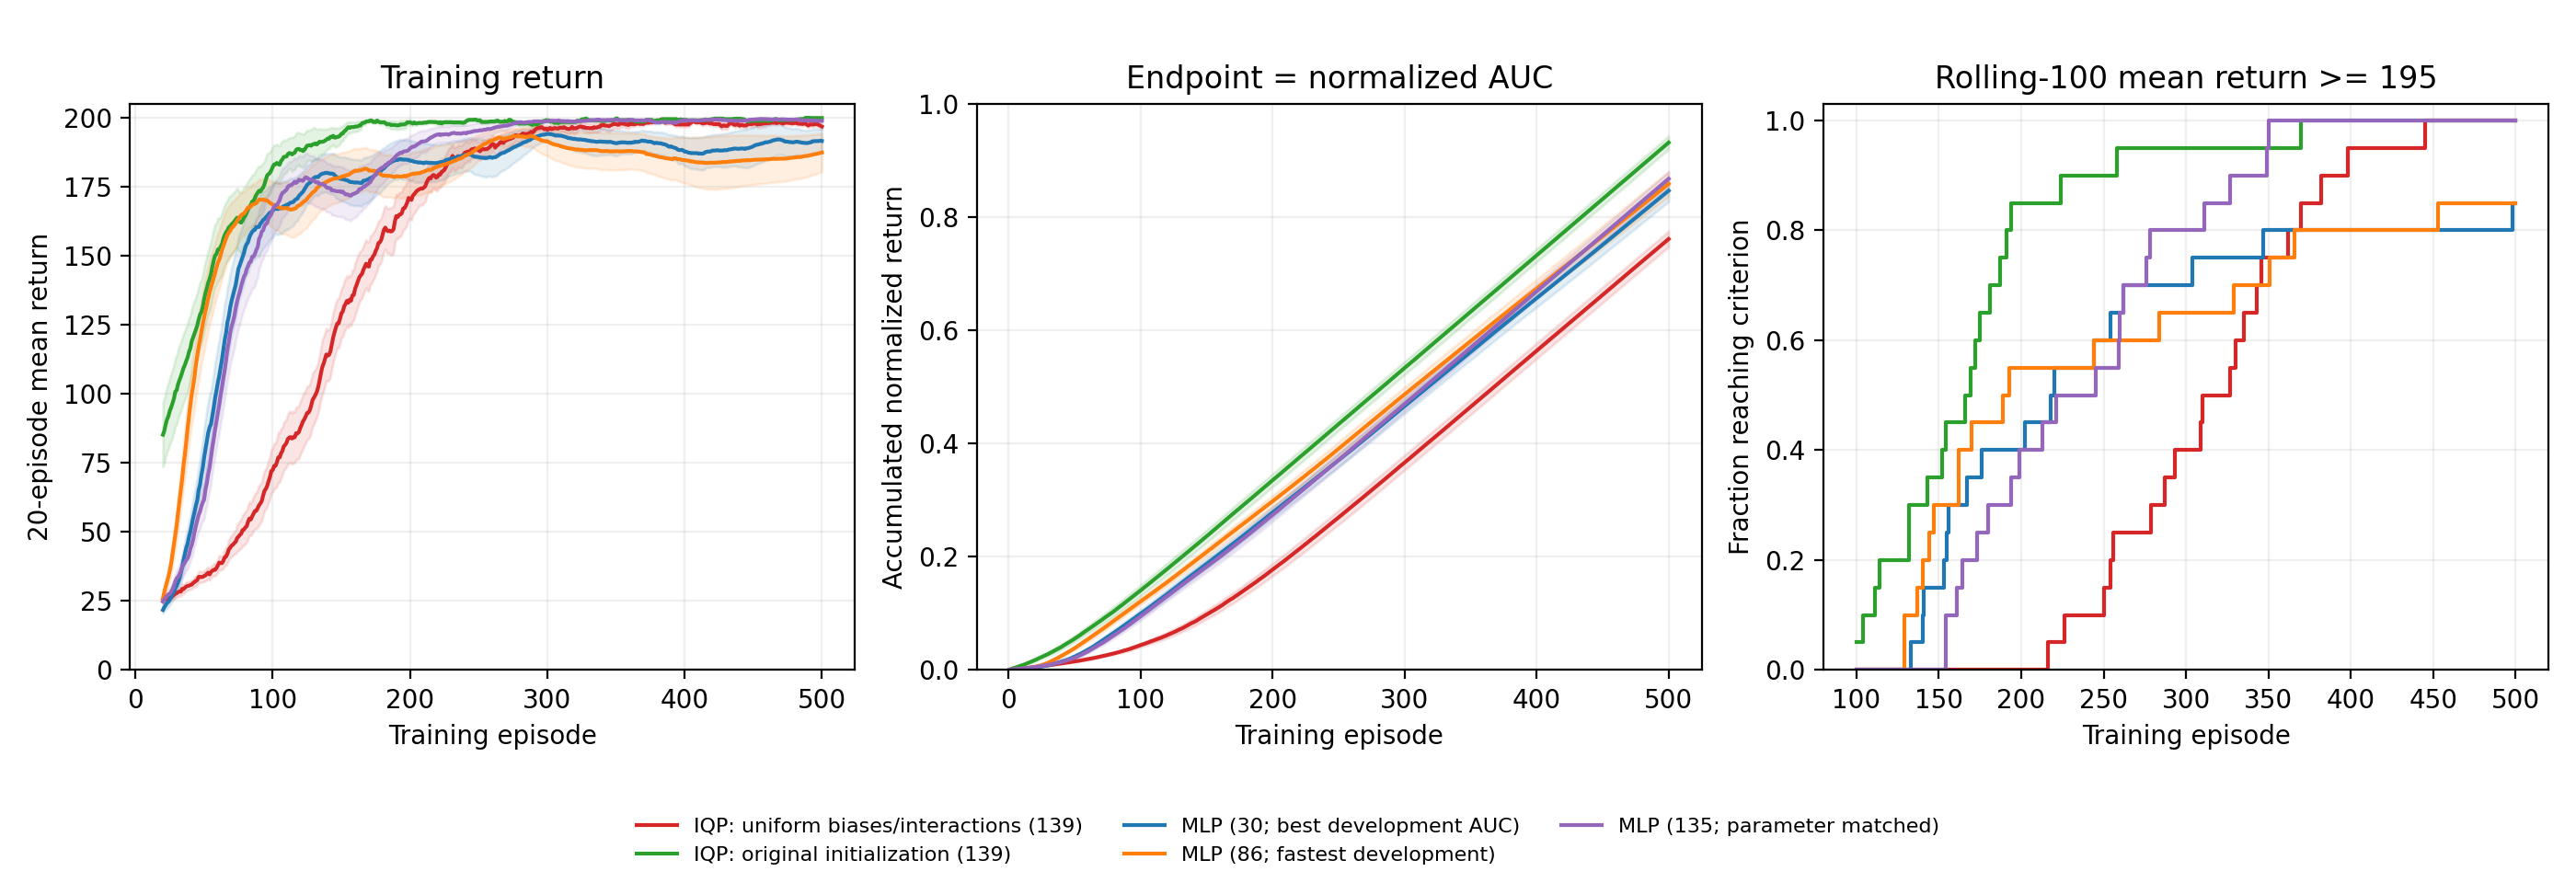

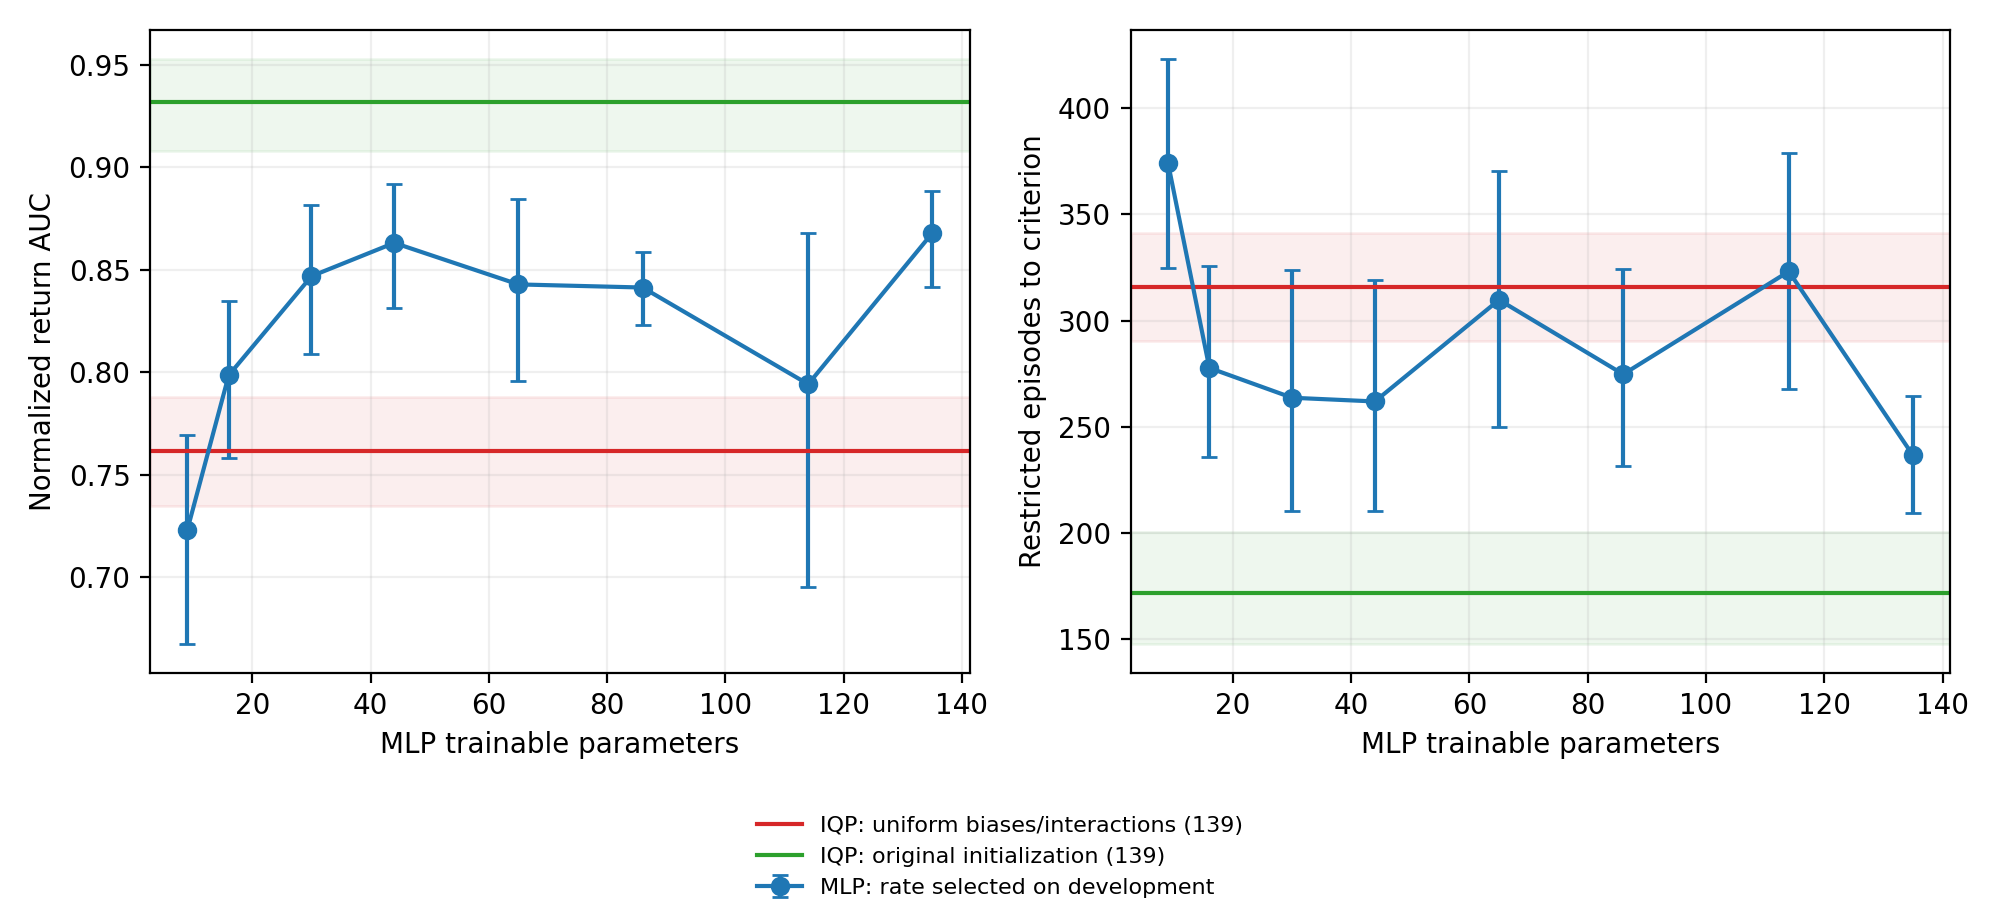

In [2]:
display(Image(filename=str(FOLDER/'initialization_comparison.png')))
display(Image(filename=str(FOLDER/'initialization_mlp_size_comparison.png')))


In [3]:
print(json.dumps(json.loads((FOLDER/'protocol.json').read_text()), indent=2))


{
  "model": "iqp_connected_uniform",
  "parameters": 139,
  "qubits": 21,
  "changed": "All 21 trainable biases, 28 intra-triple interaction angles and 6 bridge angles initialized independently Uniform[-pi,pi].",
  "unchanged": "Exact connected circuit, global majority, common neural weights bitwise identical per seed, preprocessing, REINFORCE objective and optimizer, learning rate .03, 500 episodes with 200-step limit, five-episode batches, corrected full-100-window freezing rule, and evaluation seed mappings.",
  "neural_weights": "Original Uniform[0,2pi) weights, unchanged, not Uniform[-pi,pi].",
  "initialization_stream_offsets": {
    "bias": 1900000,
    "interactions": 2000000,
    "bridges": 2100000
  },
  "seeds": [
    2001,
    2002,
    2003,
    2004,
    2005,
    2006,
    2007,
    2008,
    2009,
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020
  ],
  "evaluation_episodes": 100,
  "initial_audit_episodes": 10